In [25]:
import pandas as pd
data = pd.read_csv('../data/properties.csv').iloc[:, 1:]
data.head()

,id,url,latitude,longitude,street_address,suburb,postcode,state,activated_at,weekly_rent_number,...,car_spaces,furnished,partially_furnished,pets_allowed,long_term_lease,is_build_to_rent,features,n_photos,walkability_score,added_at
0,6371480,https://www.rent.com.au/property/87-7-riversid...,-37.821335,144.964697,"87/7 Riverside Quay,",southbank,3006,vic,2026-05-08T11:27:48.000+08:00,10500.0,...,3,True,False,True,False,False,"{""airconditioning"": [""air-conditioning""], ""are...",30,"{""id"": 4596704, ""transit_category"": ""riders_pa...",2026-09-08 01:10:47
1,4916230,https://www.rent.com.au/property/brighton-vic-...,-37.907293,145.003843,NaN,brighton,3186,vic,2026-08-09T22:11:02.000+08:00,5000.0,...,2,True,False,True,False,False,"{""airconditioning"": [""air-conditioning"", ""duct...",4,"{""id"": 3146513, ""transit_category"": ""good_tran...",2026-09-07 20:58:31
2,6394132,https://www.rent.com.au/property/3-29-falls-cr...,-36.866179,147.273437,"3/29 Falls Creek Road,",falls creek,3699,vic,2026-06-02T20:17:39.000+08:00,4680.0,...,0,True,False,False,False,False,"{""kitchen"": [""dishwasher""]}",17,"{""id"": 4619301, ""transit_category"": ""minimal_t...",2026-09-07 22:15:49
3,4916219,https://www.rent.com.au/property/brighton-vic-...,-37.925996,144.988343,NaN,brighton,3186,vic,2026-08-23T12:36:02.000+08:00,4200.0,...,2,True,False,True,False,False,"{""airconditioning"": [""air-conditioning""], ""are...",25,"{""id"": 3146501, ""transit_category"": ""good_tran...",2026-09-07 20:58:31
4,4916229,https://www.rent.com.au/property/brighton-vic-...,-37.926184,144.988267,NaN,brighton,3186,vic,2026-08-23T12:36:03.000+08:00,4200.0,...,2,True,False,True,False,False,"{""airconditioning"": [""air-conditioning"", ""duct...",22,"{""id"": 3146511, ""transit_category"": ""good_tran...",2026-09-07 20:58:31


# Checking for missing values, unique values, etc.


In [26]:
print(f"Number of unique values in 'state': {data['state'].nunique()}")
data.isna().any()

Number of unique values in 'state': 1


id                     False
url                    False
latitude               False
longitude              False
street_address          True
suburb                 False
postcode               False
state                  False
activated_at            True
weekly_rent_number     False
property_type          False
bedrooms               False
bathrooms              False
ensuites                True
car_spaces             False
furnished              False
partially_furnished    False
pets_allowed            True
long_term_lease        False
is_build_to_rent       False
features               False
n_photos               False
walkability_score      False
added_at               False
dtype: bool

In [27]:
print(data.dtypes)

id                       int64
url                        str
latitude               float64
longitude              float64
street_address             str
suburb                     str
postcode                 int64
state                      str
activated_at               str
weekly_rent_number     float64
property_type              str
bedrooms                 int64
bathrooms                int64
ensuites               float64
car_spaces               int64
furnished                 bool
partially_furnished       bool
pets_allowed            object
long_term_lease           bool
is_build_to_rent          bool
features                   str
n_photos                 int64
walkability_score          str
added_at                   str
dtype: object


# Investigating `weekly_rent_number`

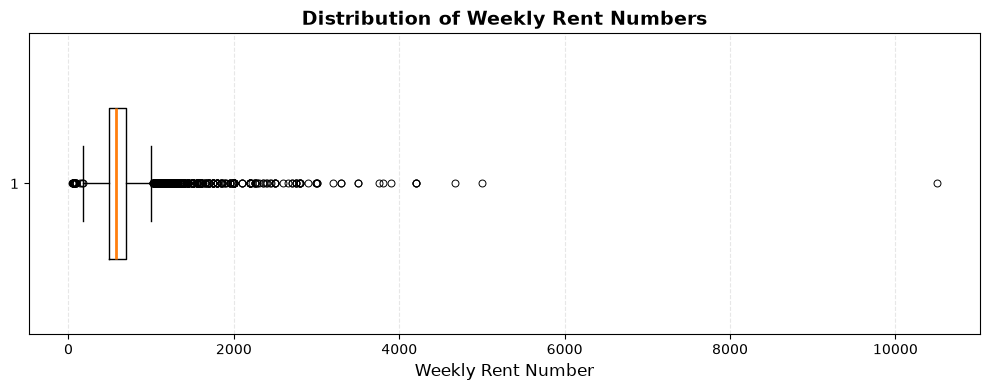

In [28]:
import matplotlib.pyplot as plt

# Create figure with appropriate size
plt.figure(figsize=(10, 4))

# Create boxplot with thicker lines
plt.boxplot(data['weekly_rent_number'], 
            orientation='horizontal',
            widths=0.5,
            boxprops=dict(linewidth=1),
            whiskerprops=dict(linewidth=1),
            capprops=dict(linewidth=1),
            medianprops=dict(linewidth=2),
            flierprops=dict(marker='o', markersize=5, markeredgewidth=0.7))

# Add labels and title
plt.xlabel('Weekly Rent Number', fontsize=12)
plt.title('Distribution of Weekly Rent Numbers', fontsize=14, fontweight='bold')

# Add grid behind the plot
plt.grid(True, axis='x', alpha=0.3, linestyle='--')

plt.tight_layout()
plt.show()

In [29]:
max_rent = data['weekly_rent_number'].max()
data.loc[data['weekly_rent_number'] == max_rent]

,id,url,latitude,longitude,street_address,suburb,postcode,state,activated_at,weekly_rent_number,...,car_spaces,furnished,partially_furnished,pets_allowed,long_term_lease,is_build_to_rent,features,n_photos,walkability_score,added_at
0,6371480,https://www.rent.com.au/property/87-7-riversid...,-37.821335,144.964697,"87/7 Riverside Quay,",southbank,3006,vic,2026-05-08T11:27:48.000+08:00,10500.0,...,3,True,False,True,False,False,"{""airconditioning"": [""air-conditioning""], ""are...",30,"{""id"": 4596704, ""transit_category"": ""riders_pa...",2026-09-08 01:10:47


Searching online shows that the extreme outlier is a real rental property in Southbank. We choose to keep this value in our model on the basis that it is a valid rent value. However in the modelling stage, we will have to investigate whether this data point is worth keeping based on its influence.

# Performing the data cleaning steps

In [30]:
cleaned_data = data.copy()
# drop the 'state' column as it has only one unique value
cleaned_data.drop(columns=['state'], inplace=True)
# replace NULLs in 'ensuites' with 0
cleaned_data = cleaned_data.fillna({'ensuites': 0})
cleaned_data.head()

,id,url,latitude,longitude,street_address,suburb,postcode,activated_at,weekly_rent_number,property_type,...,car_spaces,furnished,partially_furnished,pets_allowed,long_term_lease,is_build_to_rent,features,n_photos,walkability_score,added_at
0,6371480,https://www.rent.com.au/property/87-7-riversid...,-37.821335,144.964697,"87/7 Riverside Quay,",southbank,3006,2026-05-08T11:27:48.000+08:00,10500.0,Other,...,3,True,False,True,False,False,"{""airconditioning"": [""air-conditioning""], ""are...",30,"{""id"": 4596704, ""transit_category"": ""riders_pa...",2026-09-08 01:10:47
1,4916230,https://www.rent.com.au/property/brighton-vic-...,-37.907293,145.003843,NaN,brighton,3186,2026-08-09T22:11:02.000+08:00,5000.0,Unit,...,2,True,False,True,False,False,"{""airconditioning"": [""air-conditioning"", ""duct...",4,"{""id"": 3146513, ""transit_category"": ""good_tran...",2026-09-07 20:58:31
2,6394132,https://www.rent.com.au/property/3-29-falls-cr...,-36.866179,147.273437,"3/29 Falls Creek Road,",falls creek,3699,2026-06-02T20:17:39.000+08:00,4680.0,Apartment,...,0,True,False,False,False,False,"{""kitchen"": [""dishwasher""]}",17,"{""id"": 4619301, ""transit_category"": ""minimal_t...",2026-09-07 22:15:49
3,4916219,https://www.rent.com.au/property/brighton-vic-...,-37.925996,144.988343,NaN,brighton,3186,2026-08-23T12:36:02.000+08:00,4200.0,Townhouse,...,2,True,False,True,False,False,"{""airconditioning"": [""air-conditioning""], ""are...",25,"{""id"": 3146501, ""transit_category"": ""good_tran...",2026-09-07 20:58:31
4,4916229,https://www.rent.com.au/property/brighton-vic-...,-37.926184,144.988267,NaN,brighton,3186,2026-08-23T12:36:03.000+08:00,4200.0,Townhouse,...,2,True,False,True,False,False,"{""airconditioning"": [""air-conditioning"", ""duct...",22,"{""id"": 3146511, ""transit_category"": ""good_tran...",2026-09-07 20:58:31


In [31]:
proportion_null = len(cleaned_data.loc[cleaned_data['street_address'].isnull()]) / len(cleaned_data)
print(f"Proportion of null values in 'street_address': {proportion_null:.2%}")

# given the proportion of null values in 'street_address' is less than 5%, we can drop the rows with null values in this column
print('Shape of cleaned_data before dropping null values in street_address:', cleaned_data.shape)
cleaned_data.dropna(subset=['street_address'], inplace=True)
print('Shape of cleaned_data after dropping null values in street_address:', cleaned_data.shape)

# also drop the column 'n_photos' as it serves no purpose in our analysis
cleaned_data.drop(columns=['n_photos'], inplace=True)

Proportion of null values in 'street_address': 0.81%
Shape of cleaned_data before dropping null values in street_address: (9220, 23)
Shape of cleaned_data after dropping null values in street_address: (9145, 23)


In [32]:
import json
cleaned_data["transit_score"] = cleaned_data["walkability_score"].apply(
    lambda x: json.loads(x)["transit_score"]
)

cleaned_data["walk_score"] = cleaned_data["walkability_score"].apply(
    lambda x: json.loads(x)["walk_score"]
)
# drop the original 'walkability_score' column as we have extracted the relevant information
cleaned_data.drop(columns=['walkability_score'], inplace=True)
cleaned_data.head()

,id,url,latitude,longitude,street_address,suburb,postcode,activated_at,weekly_rent_number,property_type,...,car_spaces,furnished,partially_furnished,pets_allowed,long_term_lease,is_build_to_rent,features,added_at,transit_score,walk_score
0,6371480,https://www.rent.com.au/property/87-7-riversid...,-37.821335,144.964697,"87/7 Riverside Quay,",southbank,3006,2026-05-08T11:27:48.000+08:00,10500.0,Other,...,3,True,False,True,False,False,"{""airconditioning"": [""air-conditioning""], ""are...",2026-09-08 01:10:47,100,99.0
2,6394132,https://www.rent.com.au/property/3-29-falls-cr...,-36.866179,147.273437,"3/29 Falls Creek Road,",falls creek,3699,2026-06-02T20:17:39.000+08:00,4680.0,Apartment,...,0,True,False,False,False,False,"{""kitchen"": [""dishwasher""]}",2026-09-07 22:15:49,0,38.0
5,5965170,https://www.rent.com.au/property/901-161-easte...,-37.836644,144.967268,"901/161 Eastern Road,",south melbourne,3205,2026-06-05T12:11:54.000+08:00,4200.0,Apartment,...,4,True,False,False,False,False,"{""airconditioning"": [""air-conditioning""], ""are...",2026-09-08 00:53:44,93,93.0
6,6425253,https://www.rent.com.au/property/2301-15-carav...,-37.814211,144.941697,"2301/15 Caravel Lane,",docklands,3008,2026-07-07T11:41:55.000+08:00,3900.0,Apartment,...,5,False,False,NaN,False,False,"{""airconditioning"": [""air-conditioning"", ""duct...",2026-09-07 21:58:09,100,95.0
7,6457336,https://www.rent.com.au/property/g1-63-heyingt...,-37.834188,145.021531,"G1/63 Heyington Place,",toorak,3142,2026-08-12T09:37:26.000+08:00,3800.0,Apartment,...,3,True,False,NaN,False,False,"{""airconditioning"": [""air-conditioning"", ""duct...",2026-09-08 01:44:09,69,29.0


In [33]:
# replace 'Melbourne' with 'CBD' in the 'suburb' column
cleaned_data.loc[
    cleaned_data["suburb"].str.lower() == "melbourne",
    "suburb"
] = "CBD"
# remove 'added_at' as this is a bookkeeping column and does not serve any purpose in our analysis
cleaned_data.drop(columns=['added_at'], inplace=True)
# also remove 'activated_at' for the same reason
cleaned_data.drop(columns=['activated_at'], inplace=True)
# also remove the URL column as it is not relevant to our analysis
cleaned_data.drop(columns=['url'], inplace=True)
# rename the 'id' column to 'property_id' for better clarity
cleaned_data.rename(columns={'id': 'property_id'}, inplace=True)
cleaned_data.head()

,property_id,latitude,longitude,street_address,suburb,postcode,weekly_rent_number,property_type,bedrooms,bathrooms,ensuites,car_spaces,furnished,partially_furnished,pets_allowed,long_term_lease,is_build_to_rent,features,transit_score,walk_score
0,6371480,-37.821335,144.964697,"87/7 Riverside Quay,",southbank,3006,10500.0,Other,3,3,0.0,3,True,False,True,False,False,"{""airconditioning"": [""air-conditioning""], ""are...",100,99.0
2,6394132,-36.866179,147.273437,"3/29 Falls Creek Road,",falls creek,3699,4680.0,Apartment,3,1,0.0,0,True,False,False,False,False,"{""kitchen"": [""dishwasher""]}",0,38.0
5,5965170,-37.836644,144.967268,"901/161 Eastern Road,",south melbourne,3205,4200.0,Apartment,4,3,1.0,4,True,False,False,False,False,"{""airconditioning"": [""air-conditioning""], ""are...",93,93.0
6,6425253,-37.814211,144.941697,"2301/15 Caravel Lane,",docklands,3008,3900.0,Apartment,6,6,0.0,5,False,False,NaN,False,False,"{""airconditioning"": [""air-conditioning"", ""duct...",100,95.0
7,6457336,-37.834188,145.021531,"G1/63 Heyington Place,",toorak,3142,3800.0,Apartment,3,3,3.0,3,True,False,NaN,False,False,"{""airconditioning"": [""air-conditioning"", ""duct...",69,29.0


In [34]:
# checking for negative values in the relevant columns
cols_to_check_negs = ['weekly_rent_number', 'bedrooms', 'bathrooms', 'ensuites', 'car_spaces', 'transit_score', 'walk_score', 'transit_score']
for col in cols_to_check_negs:
    neg_values = cleaned_data[cleaned_data[col] < 0]
    if not neg_values.empty:
        print(f"Negative values found in column '{col}':")
        print(neg_values)
    else:
        print(f"No negative values found in column '{col}'.")

No negative values found in column 'weekly_rent_number'.
No negative values found in column 'bedrooms'.
No negative values found in column 'bathrooms'.
No negative values found in column 'ensuites'.
No negative values found in column 'car_spaces'.
No negative values found in column 'transit_score'.
No negative values found in column 'walk_score'.
No negative values found in column 'transit_score'.


# Considerations
Due to the complicated nature of `features`, we have kept it as-is so that the modeller has the freedom to decide how they want to utilise that feature.

In [35]:
# Convert the JSON string to dict if needed, then extract features
def extract_features(features_dict):
    """Extract flattened feature terms from the nested dictionary"""
    features_list = []
    
    if isinstance(features_dict, str):
        features_dict = json.loads(features_dict)
    
    for category, values in features_dict.items():
        for value in values:
            # Create the feature name: category_value
            feature_name = f"{category}_{value.replace(' ', '_')}"
            features_list.append(feature_name)
    
    return features_list

# Extract all features for each row
cleaned_data['extracted_features'] = cleaned_data['features'].apply(extract_features)

# One-hot encode: create a set of all unique features first
all_features = set()
for features_list in cleaned_data['extracted_features']:
    all_features.update(features_list)

# Create one-hot encoded columns
for feature in sorted(all_features):
    cleaned_data[feature] = cleaned_data['extracted_features'].apply(
        lambda x: 1 if feature in x else 0
    )

# Drop the original columns if you want
cleaned_data = cleaned_data.drop(['features', 'extracted_features'], axis=1)

print(cleaned_data.head())

   property_id   latitude   longitude           street_address  \
0      6371480 -37.821335  144.964697    87/7 Riverside Quay,    
2      6394132 -36.866179  147.273437  3/29 Falls Creek Road,    
5      5965170 -37.836644  144.967268   901/161 Eastern Road,    
6      6425253 -37.814211  144.941697   2301/15 Caravel Lane,    
7      6457336 -37.834188  145.021531  G1/63 Heyington Place,    

            suburb  postcode  weekly_rent_number property_type  bedrooms  \
0        southbank      3006             10500.0         Other         3   
2      falls creek      3699              4680.0     Apartment         3   
5  south melbourne      3205              4200.0     Apartment         4   
6        docklands      3008              3900.0     Apartment         6   
7           toorak      3142              3800.0     Apartment         3   

   bathrooms  ...  services_available_pay_tv  services_available_solar_power  \
0          3  ...                          1                      

/var/folders/9j/vx7nyby10v90568szvhwjnmr0000gq/T/ipykernel_69902/2474770304.py:27: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  cleaned_data[feature] = cleaned_data['extracted_features'].apply(


In [36]:
import os
# save the CSV file to '../data/preprocessed_data/'
os.makedirs('../data/preprocessed_data', exist_ok=True)
cleaned_data.to_csv('../data/preprocessed_data/cleaned_properties.csv', index=False)